## 1. Import libraries

We use TensorFlow/Keras to build the neural network, NumPy for numerical work, and Matplotlib to display images and graphs.

In [1]:
import os
import random
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow version:", tf.__version__)
print("Available devices:", tf.config.list_physical_devices())

TensorFlow version: 2.22.0-rc0
Available devices: [PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU')]


## 2. Load the dataset

Fashion-MNIST contains 28 × 28 pixel grayscale images. Each image has a label from 0 to 9.

In [2]:
fashion_mnist = tf.keras.datasets.fashion_mnist
(x_train, y_train), (x_test, y_test) = fashion_mnist.load_data()

class_names = [
    "T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
    "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"
]

print("Training images:", x_train.shape)
print("Training labels:", y_train.shape)
print("Test images:", x_test.shape)
print("Test labels:", y_test.shape)
print("Pixel value range before scaling:", int(x_train.min()), "to", int(x_train.max()))

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 2us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 10s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Training images: (60000, 28, 28)
Training labels: (60000,)
Test images: (10000, 28, 28)
Test labels: (10000,)
Pixel value range before scaling: 0 to 255


## 3. Explore a few images

This grid shows example images and their labels. The model will learn patterns from the pixels.

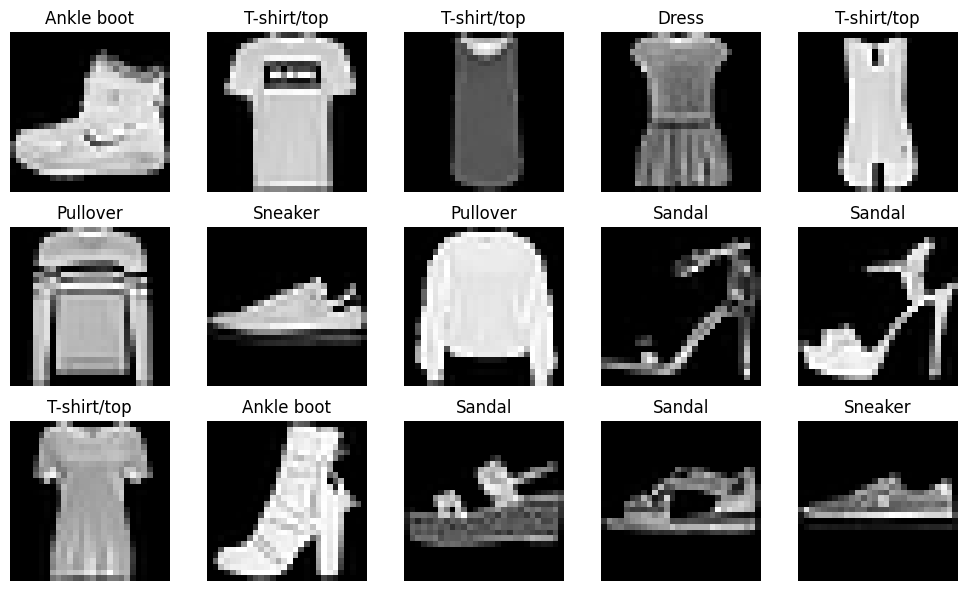

In [3]:
plt.figure(figsize=(10, 6))
for i in range(15):
    plt.subplot(3, 5, i + 1)
    plt.imshow(x_train[i], cmap="gray")
    plt.title(class_names[y_train[i]])
    plt.axis("off")
plt.tight_layout()
plt.show()

## 4. Prepare the data

Pixel values originally range from 0 to 255. Dividing by 255 scales them to 0–1, which usually helps neural networks train more smoothly. Labels are already integer class IDs, so we leave them unchanged.

In [4]:
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

print("Scaled pixel value range:", float(x_train.min()), "to", float(x_train.max()))
print("Training samples:", len(x_train))
print("Test samples:", len(x_test))

Scaled pixel value range: 0.0 to 1.0
Training samples: 60000
Test samples: 10000


## 5. Build the neural network

- `Flatten` turns each 28 × 28 image into a one-dimensional list of 784 values.
- `Dense(128, activation="relu")` learns useful image patterns.
- `Dropout` helps reduce overfitting during training.
- The output layer has 10 scores, one for each clothing category. We use logits, so the loss function is configured with `from_logits=True`.

In [5]:
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(28, 28)),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dropout(0.2),
    tf.keras.layers.Dense(10)
])

model.compile(
    optimizer="adam",
    loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    metrics=["accuracy"]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

## 6. Train the model

The model sees the training images several times. Each full pass through the training data is called an **epoch**. Validation data helps us check performance on data not used to update the model weights.

In [6]:
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True
)

history = model.fit(
    x_train,
    y_train,
    epochs=10,
    batch_size=64,
    validation_split=0.1,
    callbacks=[early_stopping],
    verbose=1
)

Epoch 1/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.8008 - loss: 0.5668 - val_accuracy: 0.8412 - val_loss: 0.4308
Epoch 2/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.8538 - loss: 0.4141 - val_accuracy: 0.8598 - val_loss: 0.3813
Epoch 3/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.8666 - loss: 0.3713 - val_accuracy: 0.8605 - val_loss: 0.3703
Epoch 4/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.8710 - loss: 0.3522 - val_accuracy: 0.8672 - val_loss: 0.3534
Epoch 5/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.8794 - loss: 0.3325 - val_accuracy: 0.8720 - val_loss: 0.3527
Epoch 6/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.8831 - loss: 0.3193 - val_accuracy: 0.8740 - val_loss: 0.3423
Epoch 7/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.8867 - loss: 0.3095 - val_accuracy: 0.8748 - val_loss: 0.3464
Epoch 8/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8899 - loss: 0.2978 - val_accuracy: 0.

## 7. Plot training history

Training and validation accuracy show how well the model is learning. If training accuracy keeps rising while validation performance worsens, that can be a sign of overfitting.

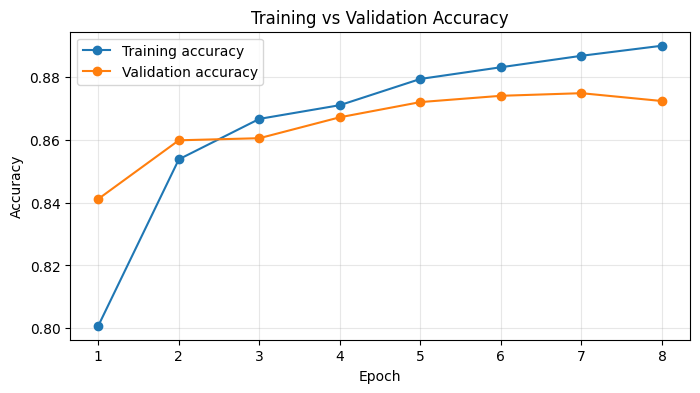

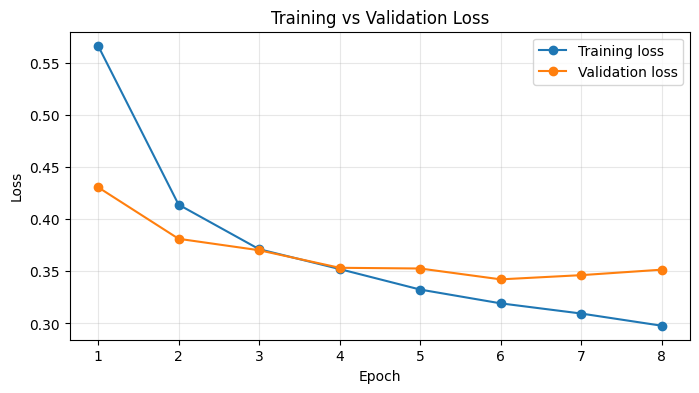

In [7]:
epochs_ran = range(1, len(history.history["accuracy"]) + 1)

plt.figure(figsize=(8, 4))
plt.plot(epochs_ran, history.history["accuracy"], marker="o", label="Training accuracy")
plt.plot(epochs_ran, history.history["val_accuracy"], marker="o", label="Validation accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training vs Validation Accuracy")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

plt.figure(figsize=(8, 4))
plt.plot(epochs_ran, history.history["loss"], marker="o", label="Training loss")
plt.plot(epochs_ran, history.history["val_loss"], marker="o", label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training vs Validation Loss")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

## 8. Evaluate on the test set

The test set is held aside until evaluation. Its accuracy gives a useful estimate of how the trained model performs on unseen examples.

In [8]:
test_loss, test_accuracy = model.evaluate(x_test, y_test, verbose=0)
print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy:.2%}")

Test loss: 0.3742
Test accuracy: 86.86%


## 9. Make predictions

The model outputs 10 logits per image. Applying softmax converts those scores to class probabilities.

In [9]:
probability_model = tf.keras.Sequential([
    model,
    tf.keras.layers.Softmax()
])

probabilities = probability_model.predict(x_test[:10], verbose=0)
predicted_labels = np.argmax(probabilities, axis=1)

for i in range(10):
    print(
        f"Image {i}: predicted={class_names[predicted_labels[i]]}, "
        f"actual={class_names[y_test[i]]}, "
        f"confidence={probabilities[i, predicted_labels[i]]:.1%}"
    )

Image 0: predicted=Ankle boot, actual=Ankle boot, confidence=94.2%
Image 1: predicted=Pullover, actual=Pullover, confidence=99.9%
Image 2: predicted=Trouser, actual=Trouser, confidence=100.0%
Image 3: predicted=Trouser, actual=Trouser, confidence=100.0%
Image 4: predicted=Shirt, actual=Shirt, confidence=68.9%
Image 5: predicted=Trouser, actual=Trouser, confidence=100.0%
Image 6: predicted=Coat, actual=Coat, confidence=99.2%
Image 7: predicted=Shirt, actual=Shirt, confidence=95.9%
Image 8: predicted=Sandal, actual=Sandal, confidence=100.0%
Image 9: predicted=Sneaker, actual=Sneaker, confidence=99.9%


## 10. Visualize predictions

Green titles indicate correct predictions; red titles indicate incorrect predictions. Confidence is the model's probability for its predicted class, not a guarantee that the prediction is correct.

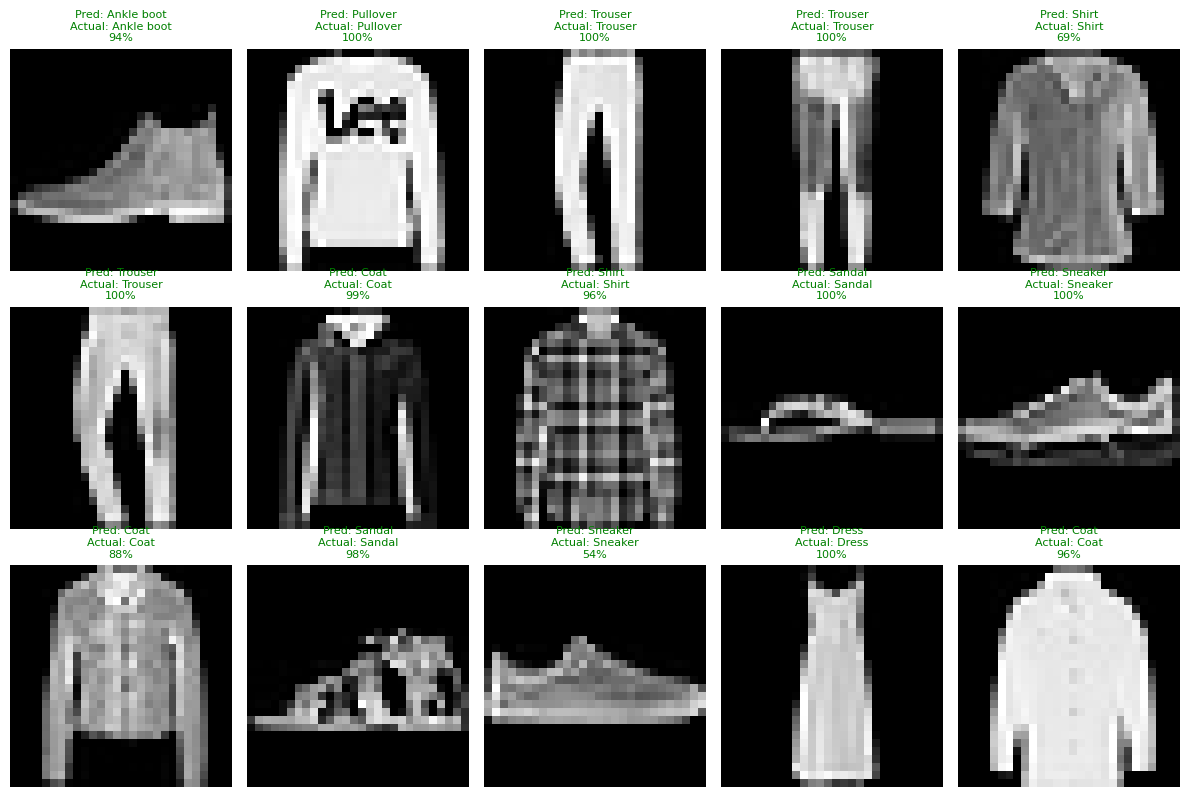

In [10]:
sample_count = 15
sample_probabilities = probability_model.predict(x_test[:sample_count], verbose=0)
sample_predictions = np.argmax(sample_probabilities, axis=1)

plt.figure(figsize=(12, 8))
for i in range(sample_count):
    plt.subplot(3, 5, i + 1)
    plt.imshow(x_test[i], cmap="gray")
    predicted = sample_predictions[i]
    actual = y_test[i]
    color = "green" if predicted == actual else "red"
    confidence = sample_probabilities[i, predicted]
    plt.title(
        f"Pred: {class_names[predicted]}\nActual: {class_names[actual]}\n{confidence:.0%}",
        color=color,
        fontsize=8
    )
    plt.axis("off")
plt.tight_layout()
plt.show()

## 11. Review class-wise performance

The table below summarizes how many test images belong to each category and the percentage correctly classified for that category.

In [11]:
predicted_test_labels = np.argmax(probability_model.predict(x_test, verbose=0), axis=1)

print(f'{"Class":<15} {"Test images":>12} {"Correct":>10} {"Accuracy":>10}')
print("-" * 50)
for class_id, class_name in enumerate(class_names):
    mask = y_test == class_id
    total = int(mask.sum())
    correct = int((predicted_test_labels[mask] == y_test[mask]).sum())
    accuracy = correct / total if total else 0.0
    print(f"{class_name:<15} {total:>12} {correct:>10} {accuracy:>9.1%}")

Class            Test images    Correct   Accuracy
--------------------------------------------------
T-shirt/top             1000        845     84.5%
Trouser                 1000        964     96.4%
Pullover                1000        751     75.1%
Dress                   1000        915     91.5%
Coat                    1000        859     85.9%
Sandal                  1000        955     95.5%
Shirt                   1000        539     53.9%
Sneaker                 1000        972     97.2%
Bag                     1000        961     96.1%
Ankle boot              1000        925     92.5%


## 12. Save the trained model

The `.keras` file stores the model architecture and learned weights. The file is saved in the notebook's current working directory.

In [12]:
model_path = "fashion_mnist_classifier.keras"
model.save(model_path)
print("Saved model to:", os.path.abspath(model_path))
print("File size (MB):", round(os.path.getsize(model_path) / (1024 * 1024), 2))

Saved model to: c:\Users\nani8\Downloads\fashion_mnist_classifier.keras
File size (MB): 1.19


## 13. Reload and verify the model

Reloading checks that the saved model can be used again. We compare its test accuracy with the earlier evaluation.

In [13]:
loaded_model = tf.keras.models.load_model(model_path)
loaded_loss, loaded_accuracy = loaded_model.evaluate(x_test, y_test, verbose=0)

print(f"Original test accuracy: {test_accuracy:.4f}")
print(f"Reloaded test accuracy: {loaded_accuracy:.4f}")
print("Accuracy difference:", abs(test_accuracy - loaded_accuracy))

Original test accuracy: 0.8686
Reloaded test accuracy: 0.8686
Accuracy difference: 0.0


## 14. Try one image yourself

Change `image_index` to any integer from `0` to `len(x_test) - 1` to inspect a different test image.

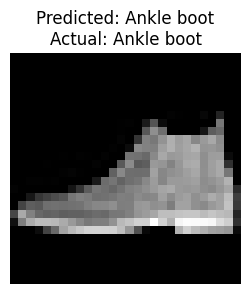

Predicted class: Ankle boot
Actual class: Ankle boot
Prediction confidence: 94.16%


In [14]:
image_index = 0  # Change this number to try another test image

single_image = x_test[image_index]
single_probabilities = probability_model.predict(single_image[np.newaxis, ...], verbose=0)[0]
predicted_class = int(np.argmax(single_probabilities))
actual_class = int(y_test[image_index])

plt.figure(figsize=(3, 3))
plt.imshow(single_image, cmap="gray")
plt.title(f"Predicted: {class_names[predicted_class]}\nActual: {class_names[actual_class]}")
plt.axis("off")
plt.show()

print("Predicted class:", class_names[predicted_class])
print("Actual class:", class_names[actual_class])
print(f"Prediction confidence: {single_probabilities[predicted_class]:.2%}")

## 15. Conclusion

- Loaded and explored a real image dataset.
- Normalized pixel values.
- Built a neural network using Keras.
- Trained with validation monitoring.
- Evaluated the model on unseen test images.
- Inspected predictions and class-wise accuracy.
- Saved, reloaded, and reused the model.
